<div class="alert alert-block alert-success">
<b> Ex - 9 : </b> . Design an LSTM based handwriting recognition model.
<b> Write a program to implement an LSTM model to recognize the handwritten text</b>
</div>

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt 

import tensorflow as tf 
from tensorflow.keras.datasets import mnist 
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense, Reshape
from tensorflow.keras.optimizers.schedules import ExponentialDecay

In [2]:

(train_images, train_labels),(test_images,test_labels) = mnist.load_data()

In [3]:
x_train = train_images.astype('float32') / 255.0
x_test = test_images.astype('float32') / 255.0


In [4]:
y_train = train_labels
y_test = test_labels

In [5]:
lstm = Sequential([
    Reshape((28,28),input_shape = (28,28)),
    LSTM(128, return_sequences = True),
    Dropout(0.2),

    LSTM(128),
    Dropout(0.2),

    Dense(64,activation='relu'),
    Dropout(0.2),
    Dense(10, activation='softmax')

])


e:\Z_Arise\rika_dl_env\Lib\site-packages\keras\src\layers\reshaping\reshape.py:39: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [6]:
# Define a learning rate schedule
lr_schedule = ExponentialDecay(
    initial_learning_rate=0.001,
    decay_steps=10000,
    decay_rate=0.9
)

In [7]:
# Compile the model
lstm.compile(
    optimizer = Adam(learning_rate=lr_schedule),
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [8]:
# Print model summary
lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ reshape (Reshape)               │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 28, 128)        │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,874 (862.79 KB)

 Trainable params: 220,874 (862.79 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Train the model
history = lstm.fit(
    x_train, y_train, epochs = 3, validation_data=(x_test, y_test)
)

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 47s 24ms/step - accuracy: 0.8752 - loss: 0.3895 - val_accuracy: 0.9657 - val_loss: 0.1118
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 20ms/step - accuracy: 0.9681 - loss: 0.1148 - val_accuracy: 0.9805 - val_loss: 0.0662
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 20ms/step - accuracy: 0.9773 - loss: 0.0817 - val_accuracy: 0.9831 - val_loss: 0.0570


In [10]:
def predict_number(input_image) :

    # Preprocess the input image (assiming its' grayscale image)
    input_image = input_image.astype('float32') / 255.0
    #  Reshape to match the model's input shape
    input_image = np.reshape(input_image, (1,28,28))

    prediction = lstm.predict(input_image)
    predicted_number = np.argmax(prediction)

    return predicted_number

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step


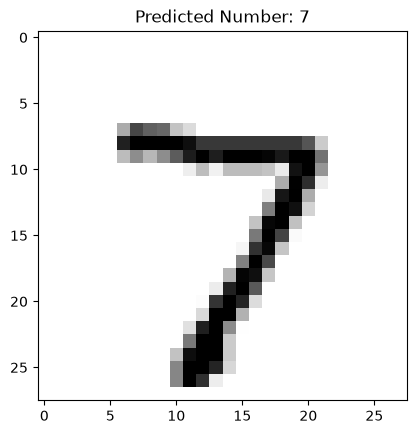

Predicted Number: 7


In [11]:
input_image = test_images[0]
predicted_number = predict_number(input_image)

plt.imshow(input_image.reshape((28,28)), cmap=plt.cm.binary)
plt.title(f"Predicted Number: {predicted_number}")
plt.show()


print("Predicted Number:", predicted_number)

In [12]:
# Assuming 'model' is your trained Keras model

# Save the trained model to the current working directory in Colab
lstm.save('my_model.h5')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step


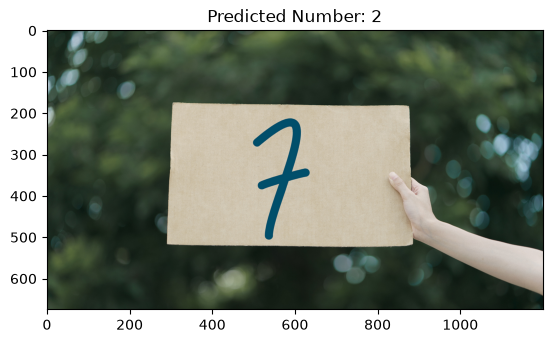

Predicted Number: 2


In [13]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
from PIL import Image

# Load your trained model (replace 'my_model.h5' with your model's filename)
model = load_model('my_model.h5')

# Define a function to predict the number from an input image file
def predict_number_from_image(image_path):
    # Load and preprocess the input image
    img = image.load_img(image_path, target_size=(28, 28), color_mode='grayscale')
    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.reshape(img_array, (1, 28, 28, 1))  # Reshape to match the model's input shape

    # Make a prediction using the trained model
    prediction = model.predict(img_array)

    # Get the index of the class with the highest probability
    predicted_number = np.argmax(prediction)

    return predicted_number

# Example usage:
# Provide an input image (as a file path)
# Replace 'your_image_path.png' with the path to your image file
# input_image_path = 'seven2.png'
input_image_path = r'E:\Z_Arise\DL\Ex_9_Handwriting_Recog_LSTM\7net3.png'

predicted_number = predict_number_from_image(input_image_path)

# Load and display the input image
img = Image.open(input_image_path)
plt.imshow(img, cmap='gray')
plt.title(f"Predicted Number: {predicted_number}")
plt.show()

# Print the predicted number
print("Predicted Number:", predicted_number)
